# Instamart Customer Intelligence

**Use case.** A quick-commerce company has messy order and customer exports. The retention team needs two things from them: **named customer segments** to design campaigns around, and a **lapse score** that says how likely each customer is to stop ordering. Nothing downstream can be trusted unless the data underneath is cleaned first, so the notebook follows that order:

| Part | Question it answers | Why it matters |
|---|---|---|
| A. Data foundation | Can we trust the numbers? | Dirty data (duplicates, pending rows, bad amounts) silently changes every later result |
| B. Segments | Who are our customers? | Different customers need different campaigns |
| B. Lapse model | Who is about to leave? | Win-back offers cost money, so aim them at the right people |

**How to run.** Put this notebook in the project root (next to `data/`, `sql/`), select the `.venv` kernel and run the cells top to bottom. It writes the same files as the `.py` scripts (`data/clean/*.csv`, `data/instamart.db`, `outputs/*`).

In [42]:
from pathlib import Path
import sqlite3
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, silhouette_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd()                      # the project root
RAW_DIR = ROOT / "data" / "raw"
CLEAN_DIR = ROOT / "data" / "clean"
DB_PATH = ROOT / "data" / "instamart.db"
OUTPUT_DIR = ROOT / "outputs"

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

---
# Part A — Data foundation

## 1. Load and audit the raw data

**What:** read the raw CSVs and measure how dirty they are (shape, types, missing values, duplicates, bad values).

**Why:** you cannot clean what you have not measured. The audit numbers also become a checklist: after cleaning, each problem should be gone. `tickets.csv` is read with `keep_default_na=False` so empty ticket texts stay empty strings instead of turning into `NaN`.

In [43]:
orders_raw = pd.read_csv(RAW_DIR / "orders.csv")
customers_raw = pd.read_csv(RAW_DIR / "customers.csv")
tickets_raw = pd.read_csv(RAW_DIR / "tickets.csv", keep_default_na=False)
products = pd.read_csv(RAW_DIR / "products.csv")

for name, df in {"orders": orders_raw, "customers": customers_raw, "tickets": tickets_raw}.items():
    print(f"\n=== {name}: shape {df.shape} ===")
    missing = df.isna().sum()
    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": missing,
        "missing_%": (missing / len(df) * 100).round(2),
    })
    display(report)


=== orders: shape (13084, 9) ===


,dtype,missing,missing_%
order_id,object,0,0.00
customer_id,object,0,0.00
product_id,object,0,0.00
quantity,int64,0,0.00
order_ts,object,0,0.00
status,object,0,0.00
discount_pct,int64,0,0.00
order_amount,object,53,0.41
delivery_minutes,float64,2541,19.42



=== customers: shape (1200, 5) ===


,dtype,missing,missing_%
customer_id,object,0,0.00
city,object,0,0.00
signup_date,object,0,0.00
age,float64,61,5.08
gender,object,30,2.50



=== tickets: shape (164, 5) ===


,dtype,missing,missing_%
ticket_id,object,0,0.0
customer_id,object,0,0.0
order_id,object,0,0.0
text,object,0,0.0
true_category,object,0,0.0


In [44]:
amounts = pd.to_numeric(orders_raw["order_amount"], errors="coerce")
delivery = pd.to_numeric(orders_raw["delivery_minutes"], errors="coerce")
age = pd.to_numeric(customers_raw["age"], errors="coerce")

audit = {
    "Raw order rows": len(orders_raw),
    "Exact duplicate rows": int(orders_raw.duplicated().sum()),
    "Pending rows": int((orders_raw["status"] == "pending").sum()),
    "Distinct order IDs": int(orders_raw["order_id"].nunique()),
    "Non-numeric order amounts": int(amounts.isna().sum()),
    "Negative delivery minutes": int((delivery < 0).sum()),
    "Blank delivery minutes": int(orders_raw["delivery_minutes"].isna().sum()),
    "Blank ages": int(customers_raw["age"].isna().sum()),
    "Ages outside 10-100": int(((age < 10) | (age > 100)).sum()),
    "Distinct raw city spellings": int(customers_raw["city"].nunique()),
    "Distinct non-blank raw gender spellings": int(customers_raw["gender"].nunique()),
    "Blank genders": int(customers_raw["gender"].isna().sum()),
}
pd.DataFrame(audit.items(), columns=["Metric", "Count"])

,Metric,Count
0,Raw order rows,13084
1,Exact duplicate rows,119
2,Pending rows,656
3,Distinct order IDs,12309
4,Non-numeric order amounts,120
5,Negative delivery minutes,106
6,Blank delivery minutes,2541
7,Blank ages,61
8,Ages outside 10-100,6
9,Distinct raw city spellings,24


## 2. Clean customers

**What:** one spelling per city, one value per gender, no impossible ages, a real date type.

**Why:** if `"pune "`, `"PUNE"` and `"Pune"` stay different, a city-level report shows three cities instead of one. Ages outside 10-100 are typing errors, so they are treated as missing and filled with the **median age of the customer's city** (`groupby` + `transform`), which is robust to outliers.

In [45]:
GENDER_MAP = {"male": "male", "m": "male", "female": "female", "f": "female"}


def clean_customers(raw):
    df = raw.copy()
    df["city"] = df["city"].str.strip().str.title()
    df["gender"] = df["gender"].str.strip().str.lower().map(GENDER_MAP).fillna("unknown")

    age = pd.to_numeric(df["age"], errors="coerce")
    age = age.mask((age < 10) | (age > 100))
    df["age"] = age.groupby(df["city"]).transform(lambda s: s.fillna(s.median()))

    df["signup_date"] = pd.to_datetime(df["signup_date"])
    return df


customers = clean_customers(customers_raw)
print(customers["city"].value_counts().to_string(), "\n")
print(customers["gender"].value_counts().to_string(), "\n")
print("Missing ages:", customers["age"].isna().sum(), "| age range:", customers["age"].min(), "to", customers["age"].max())

city
Pune         227
Delhi        210
Bengaluru    197
Chennai      191
Hyderabad    191
Mumbai       184 

gender
female     610
male       560
unknown     30 

Missing ages: 0 | age range: 18.0 to 60.0


## 3. Clean orders

**What:** apply the rules **in this order**, counting how many rows each one changes.

| # | Rule | Why |
|---|---|---|
| 1 | `order_ts` to datetime | Needed to sort by time and to compare with dates later |
| 2 | Drop exact duplicate rows | The same order exported twice would double-count revenue |
| 3 | Keep the latest record per `order_id` | An order can appear first as `pending`, then as `completed`; only the final state is real |
| 4 | Fill missing `order_amount` from price x quantity x discount | The amount can be rebuilt exactly from other columns, so no guessing |
| 5 | Negative delivery time becomes missing; completed orders get their product category's median | A negative time is impossible; the median keeps typical values |
| 6 | Cancelled orders keep missing delivery time | They were never delivered, so a filled number would be invented data |

In [46]:
def clean_orders(raw, products):
    df = raw.copy()
    changes = {}

    df["order_ts"] = pd.to_datetime(df["order_ts"])

    before = len(df)
    df = df.drop_duplicates()
    changes["exact duplicate rows removed"] = before - len(df)

    before = len(df)
    df = df.loc[df.groupby("order_id")["order_ts"].idxmax()].reset_index(drop=True)
    changes["older records of the same order_id removed"] = before - len(df)

    df = df.merge(products[["product_id", "price_inr", "category"]], on="product_id", how="left")

    df["order_amount"] = pd.to_numeric(df["order_amount"], errors="coerce")
    changes["order_amount filled from product price"] = int(df["order_amount"].isna().sum())
    rebuilt = (df["price_inr"] * df["quantity"] * (1 - df["discount_pct"] / 100)).round(2)
    df["order_amount"] = df["order_amount"].fillna(rebuilt)

    df["delivery_minutes"] = pd.to_numeric(df["delivery_minutes"], errors="coerce")
    negative = df["delivery_minutes"] < 0
    changes["negative delivery_minutes set to missing"] = int(negative.sum())
    df.loc[negative, "delivery_minutes"] = np.nan

    completed = df["status"] == "completed"
    category_median = df.loc[completed].groupby("category")["delivery_minutes"].transform("median")
    changes["completed delivery_minutes filled with category median"] = int(df.loc[completed, "delivery_minutes"].isna().sum())
    df.loc[completed, "delivery_minutes"] = df.loc[completed, "delivery_minutes"].fillna(category_median)

    return df.drop(columns=["price_inr", "category"]), changes


orders, order_changes = clean_orders(orders_raw, products)
display(pd.Series(order_changes, name="rows or values changed").to_frame())

completed = orders["status"] == "completed"
cancelled = orders["status"] == "cancelled"
print("Rows:", len(orders), "| unique order IDs:", orders["order_id"].nunique())
print(orders["status"].value_counts().to_string())
print("Missing order_amount:", orders["order_amount"].isna().sum())
print("Missing delivery (completed / cancelled):",
      orders.loc[completed, "delivery_minutes"].isna().sum(), "/", orders.loc[cancelled, "delivery_minutes"].isna().sum())
print(f"Completed revenue: INR {orders.loc[completed, 'order_amount'].sum():,.2f}")

,rows or values changed
exact duplicate rows removed,119
older records of the same order_id removed,656
order_amount filled from product price,112
negative delivery_minutes set to missing,105
completed delivery_minutes filled with category median,774


Rows: 12309 | unique order IDs: 12309
status
completed    11110
cancelled     1199
Missing order_amount: 0
Missing delivery (completed / cancelled): 0 / 1199
Completed revenue: INR 2,998,668.80


## 4. Store and validate

**What:** save the three clean tables as CSV (for pandas) and SQLite (for SQL), then check the results against the reference numbers.

**Why:** later parts read these files, so they are the single source of truth. SQLite lets us ask business questions in SQL. `order_ts` is stored as text `YYYY-MM-DD HH:MM:SS` so CSV and database agree. The validation cell is a safety net: if one number is off, you find out here and not after the model is trained.

In [47]:
orders_out = orders.copy()
orders_out["order_ts"] = orders_out["order_ts"].dt.strftime("%Y-%m-%d %H:%M:%S")
tables = {"orders": orders_out, "customers": customers, "products": products}

for name, df in tables.items():
    df.to_csv(CLEAN_DIR / f"{name}.csv", index=False)

with sqlite3.connect(DB_PATH) as conn:
    for name, df in tables.items():
        df.to_sql(name, conn, if_exists="replace", index=False)
print("Saved CSVs to", CLEAN_DIR, "and database to", DB_PATH)

city_counts = customers["city"].value_counts()
gender_counts = customers["gender"].value_counts()
checks = {
    "12,309 order rows": len(orders) == 12_309,
    "one row per order_id": orders["order_id"].nunique() == len(orders),
    "11,110 completed": completed.sum() == 11_110,
    "1,199 cancelled": cancelled.sum() == 1_199,
    "no pending rows": (orders["status"] == "pending").sum() == 0,
    "no missing order_amount": orders["order_amount"].isna().sum() == 0,
    "completed delivery filled": orders.loc[completed, "delivery_minutes"].isna().sum() == 0,
    "cancelled delivery left missing": orders.loc[cancelled, "delivery_minutes"].isna().sum() == 1_199,
    "completed revenue 2,998,668.80": round(orders.loc[completed, "order_amount"].sum(), 2) == 2_998_668.80,
    "six cities": customers["city"].nunique() == 6,
    "gender split 610 / 560 / 30": (gender_counts.get("female"), gender_counts.get("male"), gender_counts.get("unknown")) == (610, 560, 30),
    "no missing ages, all 18-60": customers["age"].isna().sum() == 0 and customers["age"].between(18, 60).all(),
}
for label, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", label)
if all(checks.values()):
    print("\nALL CHECKPOINTS PASSED")

Saved CSVs to /Users/alagarsamy/Documents/Instamart-Customer-Intelligence/data/clean and database to /Users/alagarsamy/Documents/Instamart-Customer-Intelligence/data/instamart.db
PASS - 12,309 order rows
PASS - one row per order_id
PASS - 11,110 completed
PASS - 1,199 cancelled
PASS - no pending rows
PASS - no missing order_amount
PASS - completed delivery filled
PASS - cancelled delivery left missing
PASS - completed revenue 2,998,668.80
PASS - six cities
PASS - gender split 610 / 560 / 30
PASS - no missing ages, all 18-60

ALL CHECKPOINTS PASSED


## 5. SQL analysis

**What:** run the seven queries from `sql/queries.sql` against the database.

**Why:** these are the questions a business analyst asks daily, and each one shows a different SQL tool:

| Query | Business question | SQL idea |
|---|---|---|
| Q1 | Which customers spend a lot on big baskets? | `WHERE` filters rows, `HAVING` filters groups |
| Q2 | Where does revenue come from (city x category)? | three-table join |
| Q3 | Which products are priced above average? | scalar subquery |
| Q4 | Who signed up but never completed an order? | `LEFT JOIN` + `IS NULL` |
| Q5 | Who spends more than the average customer? | CTE |
| Q6 | Who are the top spenders in each city? | `RANK`, `DENSE_RANK`, `ROW_NUMBER` |
| Q7 | How does revenue build up day by day? | running total window |

In [48]:
sql_text = (ROOT / "sql" / "queries.sql").read_text().replace("\r\n", "\n")
parts = re.split(r"^--\s*(?:name:\s*)?(Q\d+)\b[^\n]*$", sql_text, flags=re.MULTILINE | re.IGNORECASE)
queries = {name.upper(): body.strip() for name, body in zip(parts[1::2], parts[2::2])}

with sqlite3.connect(DB_PATH) as conn:
    results = {name: pd.read_sql_query(sql, conn) for name, sql in queries.items()}

print("Q1 customers:", len(results["Q1"]), "(reference 30)")
print("Q2 rows:", len(results["Q2"]), "| total INR", f"{results['Q2']['revenue'].sum():,.2f}")
print("Q3 products:", len(results["Q3"]), "(reference 11)")
print("Q4 customers:", len(results["Q4"]), "(reference 25)")
print("Q5 customers:", len(results["Q5"]), "(reference 550), average INR", results["Q5"]["avg_spend"].iloc[0])
q6 = results["Q6"]
print("Q6 rows where RANK differs from ROW_NUMBER:", int((q6["spend_rank"] != q6["spend_row_number"]).sum()), "(reference 8)")
print("Q7 daily rows:", len(results["Q7"]), "| last cumulative INR", f"{results['Q7']['cumulative_revenue'].iloc[-1]:,.2f}")
display(q6[q6["spend_row_number"] == 1][["city", "customer_id", "total_spend"]])

Q1 customers: 30 (reference 30)
Q2 rows: 30 | total INR 2,998,668.80
Q3 products: 11 (reference 11)
Q4 customers: 25 (reference 25)
Q5 customers: 550 (reference 550), average INR 2552.06
Q6 rows where RANK differs from ROW_NUMBER: 8 (reference 8)
Q7 daily rows: 183 | last cumulative INR 2,998,668.80


,city,customer_id,total_spend
0,Bengaluru,C0082,12856.20
192,Chennai,C0930,10151.40
379,Delhi,C0291,13742.60
584,Hyderabad,C0743,12730.05
771,Mumbai,C0693,14766.55
954,Pune,C0426,10377.10


## 6. pandas cross-check and exploratory analysis

**What:** rebuild Q2 in pandas, then describe the distribution of order amounts.

**Why:** two independent tools giving the same total (INR 2,998,668.80) is the cheapest proof that the numbers are right. The distribution tells us which statistics to trust: when data is right-skewed, the **median** describes a typical order better than the mean, and extreme orders need a deliberate decision (keep or remove).

In [49]:
completed_orders = orders[orders["status"] == "completed"]
merged = (completed_orders
          .merge(customers[["customer_id", "city"]], on="customer_id")
          .merge(products[["product_id", "category"]], on="product_id"))

pivot = pd.pivot_table(merged, values="order_amount", index="city", columns="category",
                       aggfunc="sum", margins=True, margins_name="Total").round(2)
display(pivot)
print(f"Pivot grand total: INR {pivot.loc['Total', 'Total']:,.2f}  (SQL total: INR {results['Q2']['revenue'].sum():,.2f})")

city_summary = (merged.groupby("city")
                .agg(total=("order_amount", "sum"), average=("order_amount", "mean"), orders=("order_amount", "count"))
                .round(2))
display(city_summary)

category,Dairy,Electronics,Grocery,Personal Care,Snacks,Total
city,,,,,,
Bengaluru,87075.05,233909.45,110915.65,20193.85,71549.40,523643.40
Chennai,78301.80,195508.80,93817.45,27675.40,68325.70,463629.15
Delhi,117271.70,158549.10,112658.05,23471.50,90879.45,502829.80
Hyderabad,83731.00,228913.10,109475.40,24800.05,81670.35,528589.90
Mumbai,75209.85,214738.40,78970.15,38018.00,72122.10,479058.50
Pune,90349.55,187629.25,108456.60,34275.15,80207.50,500918.05
Total,531938.95,1219248.10,614293.30,168433.95,464754.50,2998668.80


Pivot grand total: INR 2,998,668.80  (SQL total: INR 2,998,668.80)


,total,average,orders
city,,,
Bengaluru,523643.40,276.47,1894
Chennai,463629.15,272.72,1700
Delhi,502829.80,243.62,2064
Hyderabad,528589.90,284.95,1855
Mumbai,479058.50,297.00,1613
Pune,500918.05,252.48,1984


mean 269.91 | median 135.00 | skewness 4.61
Q1 64.80 | Q3 297.00 | fences -283.50 / 645.30
outliers below lower fence: 0 | above upper fence: 897


,order_amount,discount_pct,quantity,delivery_minutes
order_amount,1.000,-0.095,0.087,-0.003
discount_pct,-0.095,1.000,-0.000,-0.010
quantity,0.087,-0.000,1.000,-0.013
delivery_minutes,-0.003,-0.010,-0.013,1.000


Strongest pair: order_amount and discount_pct (-0.095) - small, and correlation is not causation.


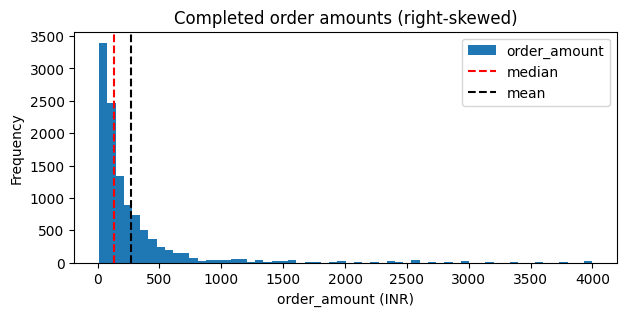

In [50]:
amount = completed_orders["order_amount"]
q1, q3 = amount.quantile(0.25), amount.quantile(0.75)
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"mean {amount.mean():.2f} | median {amount.median():.2f} | skewness {amount.skew():.2f}")
print(f"Q1 {q1:.2f} | Q3 {q3:.2f} | fences {lower_fence:.2f} / {upper_fence:.2f}")
print(f"outliers below lower fence: {(amount < lower_fence).sum()} | above upper fence: {(amount > upper_fence).sum()}")

corr = completed_orders[["order_amount", "discount_pct", "quantity", "delivery_minutes"]].corr()
display(corr.round(3))
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strongest = pairs.abs().idxmax()
print(f"Strongest pair: {strongest[0]} and {strongest[1]} ({pairs[strongest]:+.3f}) - small, and correlation is not causation.")

amount.plot.hist(bins=60, figsize=(7, 3), title="Completed order amounts (right-skewed)")
plt.axvline(amount.median(), color="red", linestyle="--", label="median")
plt.axvline(amount.mean(), color="black", linestyle="--", label="mean")
plt.xlabel("order_amount (INR)"); plt.legend(); plt.show()

---
# Part B — Customer segments and lapse prediction

## 7. Build the RFM table

**What:** one row per customer with three numbers, measured as of the snapshot **2025-10-01**.

| Column | Meaning | Reading |
|---|---|---|
| recency | days since the last completed order | low = active |
| frequency | number of distinct completed orders | high = habit |
| monetary | total completed spend | high = valuable |

**Why:** RFM is the classic way to describe customer value with three simple numbers a marketer understands. Only completed orders count, because pending or cancelled orders are not real behaviour.

In [51]:
SNAPSHOT = pd.Timestamp("2025-10-01 00:00:00")

orders = pd.read_csv(CLEAN_DIR / "orders.csv", parse_dates=["order_ts"])   # reload exactly what Part B consumes
completed_orders = orders[orders["status"] == "completed"]

rfm = completed_orders.groupby("customer_id").agg(
    last_order_ts=("order_ts", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_amount", "sum"),
)
rfm["recency"] = (SNAPSHOT - rfm["last_order_ts"]).dt.days
rfm["monetary"] = rfm["monetary"].round(2)
rfm = rfm[["recency", "frequency", "monetary"]].reset_index()

print("Customers:", len(rfm), "(reference 1,175)")
display(rfm.describe().round(2))

Customers: 1175 (reference 1,175)


,recency,frequency,monetary
count,1175.00,1175.00,1175.00
mean,33.56,9.46,2552.06
std,38.43,8.01,2367.31
min,0.00,1.00,12.00
25%,6.00,3.00,505.45
50%,19.00,5.00,2286.50
75%,46.00,17.00,3751.52
max,180.00,33.00,14766.55


## 8. Cluster with K-means

**What:** standardise the three columns, then try K = 2 to 8 clusters and record **inertia** (how tight the clusters are) and the **silhouette score** (how well separated they are).

**Why standardise:** monetary is in thousands and recency in tens; without scaling, K-means would only look at monetary.

**Why not just pick the lowest inertia:** inertia always falls when K grows (more centres means every point sits closer to one), so K = 8 beats K = 2 even if the extra clusters mean nothing. We read the **elbow** (where the drop flattens), the **silhouette** (higher is better) and **business use** (can the team run a different campaign for each group?).

/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_

,K,inertia,silhouette
0,2,1820.8,0.465
1,3,1268.2,0.445
2,4,743.1,0.526
3,5,617.4,0.480
4,6,503.2,0.482
5,7,408.5,0.416
6,8,366.5,0.412


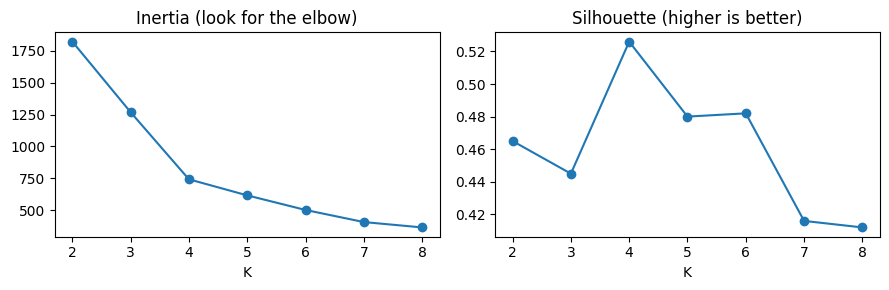

In [52]:
scaled = StandardScaler().fit_transform(rfm[["recency", "frequency", "monetary"]])

rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(scaled)
    rows.append({"K": k, "inertia": round(model.inertia_, 1), "silhouette": round(silhouette_score(scaled, labels), 3)})
k_table = pd.DataFrame(rows)
display(k_table)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(k_table["K"], k_table["inertia"], marker="o"); axes[0].set_title("Inertia (look for the elbow)")
axes[1].plot(k_table["K"], k_table["silhouette"], marker="o"); axes[1].set_title("Silhouette (higher is better)")
for ax in axes:
    ax.set_xlabel("K")
plt.tight_layout(); plt.show()

**Choice: K = 4.** The inertia drops steeply until K = 4 and flattens after it, K = 4 has the best silhouette in the reference table, and four groups are few enough for a team to act on. Change `CHOSEN_K` below if your own table points elsewhere.

## 9. Profile, name and project the segments

**What:** fit the final model, describe each segment by its average recency, frequency and monetary value, give each a business name and one action, and mark the **Premium** segment (highest mean monetary).

**Why:** a cluster number means nothing to a marketer. Cluster numbers are only labels with no order (cluster 0 is not "worse" than cluster 3), so names are assigned from the averages, never from the numbers. **PCA** squeezes the three RFM columns into two so we can draw the segments on a plane and check the groups look separate.

In [53]:
CHOSEN_K = 4

final_model = KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=RANDOM_STATE)
rfm["segment_id"] = final_model.fit_predict(scaled)

profile = rfm.groupby("segment_id").agg(
    size=("customer_id", "count"),
    recency=("recency", "mean"),
    frequency=("frequency", "mean"),
    monetary=("monetary", "mean"),
).round(2)

ACTIONS = {
    "Premium Big Spenders": "Personal offers and early access; protect with a loyalty tier.",
    "Loyal Regulars": "Reward with points and cross-sell other categories.",
    "Slipping Away": "Send a win-back coupon before they are gone for good.",
    "Occasional Shoppers": "Nudge towards a second order with a free-delivery threshold.",
}


def name_segments(profile):
    names, left = {}, profile.copy()
    premium_id = left["monetary"].idxmax()                 # highest mean monetary = Premium
    names[premium_id] = "Premium Big Spenders"
    left = left.drop(premium_id)
    slipping_id = left["recency"].idxmax()                  # longest since last order
    names[slipping_id] = "Slipping Away"
    left = left.drop(slipping_id)
    loyal_id = left["frequency"].idxmax()                   # orders most often
    names[loyal_id] = "Loyal Regulars"
    left = left.drop(loyal_id)
    names[left.index[0]] = "Occasional Shoppers"
    return names, premium_id


names, premium_id = name_segments(profile)
rfm["segment_name"] = rfm["segment_id"].map(names)
rfm["is_premium"] = rfm["segment_id"] == premium_id

profile["segment_name"] = profile.index.map(names)
profile["action"] = profile["segment_name"].map(ACTIONS)
display(profile)

/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_

,size,recency,frequency,monetary,segment_name,action
segment_id,,,,,,
0,436,28.86,3.77,1057.62,Occasional Shoppers,Nudge towards a second order with a free-deliv...
1,138,24.12,6.77,7129.70,Premium Big Spenders,Personal offers and early access; protect with...
2,419,8.77,19.40,3410.02,Loyal Regulars,Reward with points and cross-sell other catego...
3,182,109.04,2.20,685.99,Slipping Away,Send a win-back coupon before they are gone fo...


PCA explained variance: 0.634 + 0.218 = 0.852


/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


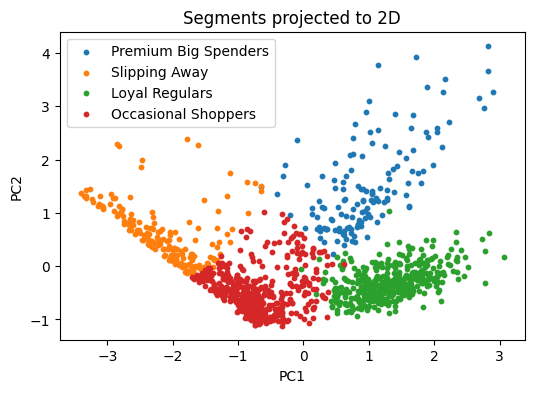

In [54]:
pca = PCA(n_components=2).fit(scaled)
ratios = pca.explained_variance_ratio_
print(f"PCA explained variance: {ratios[0]:.3f} + {ratios[1]:.3f} = {ratios.sum():.3f}")

points = pca.transform(scaled)
plt.figure(figsize=(6, 4))
for seg_id, seg_name in names.items():
    mask = (rfm["segment_id"] == seg_id).to_numpy()
    plt.scatter(points[mask, 0], points[mask, 1], s=10, label=seg_name)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Segments projected to 2D"); plt.legend(); plt.show()

columns = ["customer_id", "recency", "frequency", "monetary", "segment_id", "segment_name", "is_premium"]
rfm[columns].to_csv(OUTPUT_DIR / "customer_segments.csv", index=False)

## 10. Define the lapse problem

**What:** predict, for each customer, whether they will place **no** completed order in September 2025. The cutoff is **2025-09-01**.

**Why:** a segment describes who a customer *is*; a lapse score says who is *about to leave*, so the team can act before they do. The setup mimics real life: standing at 1 September we know only the past, and we are asked about the future.

**The most important rule - no leakage.** Features use **only orders before the cutoff**. Using September orders, or the segment labels from step 9 (which were computed from all orders including September), would let the model peek at the answer and look brilliant on paper but fail in real use.

In [55]:
CUTOFF = pd.Timestamp("2025-09-01")
WINDOW_END = pd.Timestamp("2025-10-01")

customers = pd.read_csv(CLEAN_DIR / "customers.csv", parse_dates=["signup_date"])
products = pd.read_csv(CLEAN_DIR / "products.csv")
orders_cat = orders.merge(products[["product_id", "category"]], on="product_id", how="left")

before = orders_cat[orders_cat["order_ts"] < CUTOFF]
done = before[before["status"] == "completed"]
cancelled_before = before[before["status"] == "cancelled"]

cohort = done.groupby("customer_id").agg(
    last_order_ts=("order_ts", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_amount", "sum"),
    avg_discount_pct=("discount_pct", "mean"),
    avg_delivery_minutes=("delivery_minutes", "mean"),
    favourite_category=("category", lambda s: s.mode().iloc[0]),
)
cohort["recency"] = (CUTOFF - cohort["last_order_ts"]).dt.days

n_cancelled = cancelled_before.groupby("customer_id").size().reindex(cohort.index, fill_value=0)
cohort["cancellation_rate"] = n_cancelled / (cohort["frequency"] + n_cancelled)

cohort = cohort.reset_index().merge(
    customers[["customer_id", "city", "age", "gender", "signup_date"]], on="customer_id", how="left")
cohort["tenure_days"] = (CUTOFF - cohort["signup_date"]).dt.days

september = orders_cat[(orders_cat["status"] == "completed")
                       & (orders_cat["order_ts"] >= CUTOFF) & (orders_cat["order_ts"] < WINDOW_END)]
cohort["lapsed"] = (~cohort["customer_id"].isin(september["customer_id"])).astype(int)

print(f"Cohort: {len(cohort)} customers, {cohort['lapsed'].sum()} lapsed ({cohort['lapsed'].mean():.2%})")
display(cohort.head())

Cohort: 1156 customers, 443 lapsed (38.32%)


,customer_id,last_order_ts,frequency,monetary,avg_discount_pct,avg_delivery_minutes,favourite_category,recency,cancellation_rate,city,age,gender,signup_date,tenure_days,lapsed
0,C0001,2025-07-29 22:27:32,2,378.00,10.000000,28.000000,Grocery,33,0.000000,Chennai,35.0,male,2024-01-13,597,0
1,C0002,2025-08-09 15:37:26,6,3946.90,6.666667,21.916667,Electronics,22,0.000000,Delhi,31.0,male,2024-02-17,562,0
2,C0003,2025-08-30 17:48:19,20,3264.05,12.750000,24.200000,Grocery,1,0.000000,Bengaluru,18.0,female,2025-02-18,195,0
3,C0004,2025-07-20 21:36:50,3,272.25,11.666667,35.666667,Snacks,42,0.400000,Bengaluru,24.0,female,2024-06-21,437,0
4,C0005,2025-05-06 21:44:20,2,324.00,25.000000,26.000000,Dairy,117,0.333333,Bengaluru,25.0,female,2024-10-01,335,1


## 11. Split and preprocess without leakage

**What:** hold out 20% of customers as a test set, then build a `Pipeline` that scales the numeric columns and one-hot encodes the text columns.

**Why a Pipeline:** the scaler and encoder must learn their numbers (means, categories) from the **training rows only**. If they saw the test rows, information from the "future exam" would leak into training. A pipeline fitted on training data and merely *applied* to the test data guarantees that. `drop="first"` keeps k-1 columns per category, which avoids duplicated information.

In [56]:
NUMERIC = ["recency", "frequency", "monetary", "avg_discount_pct", "cancellation_rate",
           "avg_delivery_minutes", "age", "tenure_days"]
CATEGORICAL = ["city", "gender", "favourite_category"]

X = cohort[NUMERIC + CATEGORICAL]
y = cohort["lapsed"]
assert X.isna().sum().sum() == 0, "a feature column has missing values"

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train rows:", len(X_train), "| test rows:", len(X_test), "(reference 924 / 232)")


def make_pipeline(model):
    prep = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORICAL),
    ])
    return Pipeline([("prep", prep), ("model", model)])


scaler = make_pipeline(LogisticRegression()).named_steps["prep"].fit(X_train).named_transformers_["num"]
print(f"Mean frequency learned by the scaler (train only): {scaler.mean_[NUMERIC.index('frequency')]:.3f}")
print(f"Mean frequency of the full cohort:                 {X['frequency'].mean():.3f}")
print("They differ because the scaler only saw the 80% training rows.")

Train rows: 924 | test rows: 232 (reference 924 / 232)
Mean frequency learned by the scaler (train only): 8.115
Mean frequency of the full cohort:                 8.029
They differ because the scaler only saw the 80% training rows.


## 12. Baseline, tuning and evaluation

**What:** compare two models against a do-nothing baseline, tune each with 5-fold cross-validation, and judge them once on the untouched test set.

**Why a baseline:** about 62% of customers do not lapse, so "predict nobody lapses" is already 62% accurate yet useless (it never finds a lapsing customer). A model is only worth using if it beats that on the **lapsed class**.

**Why F1 of the lapsed class, not accuracy:** accuracy hides the minority class. Precision (of those we flag, how many really leave) and recall (of those who leave, how many we catch) matter here, and F1 balances both.

**Why GridSearchCV on a Pipeline:** each cross-validation fold refits the scaler and encoder on that fold's training part, so tuning stays leak-free. The test set is used **only after** tuning is finished.

In [57]:
def lapsed_scores(y_true, y_pred):
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def show_test_result(name, model):
    predicted = model.predict(X_test)
    scores = lapsed_scores(y_test, predicted)
    print(f"\n{name}")
    print("Confusion matrix (rows = actual 0/1, columns = predicted 0/1):")
    print(confusion_matrix(y_test, predicted))
    print(f"precision {scores['precision']:.3f} | recall {scores['recall']:.3f} | F1 {scores['f1']:.3f}")
    return scores


baseline_pred = DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)
print(f"Baseline 'nobody lapses': accuracy {accuracy_score(y_test, baseline_pred):.3f}, "
      f"lapsed F1 {f1_score(y_test, baseline_pred, zero_division=0):.3f}")

logistic_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=1000)),
    {"model__C": [0.01, 0.1, 1, 10, 100]}, cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)

forest_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
    {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [5, 10, 20]},
    cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)

print("\nLogistic regression:", logistic_search.best_params_, f"CV F1 {logistic_search.best_score_:.3f}")
print("Random forest:      ", forest_search.best_params_, f"CV F1 {forest_search.best_score_:.3f}")

Baseline 'nobody lapses': accuracy 0.616, lapsed F1 0.000


/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/alagarsamy/Documents/Instamart-Customer-


Logistic regression: {'model__C': 100} CV F1 0.651
Random forest:       {'model__max_depth': 8, 'model__min_samples_leaf': 10} CV F1 0.681


In [58]:
logistic_scores = show_test_result("Logistic regression on the test set", logistic_search.best_estimator_)
forest_scores = show_test_result("Random forest on the test set", forest_search.best_estimator_)

if forest_search.best_score_ >= logistic_search.best_score_:
    selected_name, selected = "Random forest", forest_search.best_estimator_
else:
    selected_name, selected = "Logistic regression", logistic_search.best_estimator_
print("\nSelected model (best cross-validated F1):", selected_name)


Logistic regression on the test set
Confusion matrix (rows = actual 0/1, columns = predicted 0/1):
[[111  32]
 [ 31  58]]
precision 0.644 | recall 0.652 | F1 0.648

Random forest on the test set
Confusion matrix (rows = actual 0/1, columns = predicted 0/1):
[[113  30]
 [ 31  58]]
precision 0.659 | recall 0.652 | F1 0.655

Selected model (best cross-validated F1): Random forest


/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


**Why recall leads the choice.** Missing a customer who is about to leave loses all their future orders. Wrongly sending an offer to a loyal customer costs only a small discount. So a model that catches more of the lapsing customers is worth some extra false alarms, as long as the overall F1 stays at or above 0.55.

## 13. Class-balance experiment

**What:** copy random lapsed rows in the **training set only** until both classes are equal, refit the best logistic regression, and compare on the original test set.

**Why:** lapsed customers are the minority, so the model can get lazy and under-predict them. Balancing pushes it to catch more. The test set stays untouched and unbalanced, because real life is unbalanced too.

**Expected reading:** recall rises sharply while precision does not improve. For the retention team this means *reaching more of the customers who would leave, at the price of contacting more who would have stayed* - a good trade when offers are cheap, a bad one when each offer is expensive.

In [59]:
gap = int((y_train == 0).sum() - (y_train == 1).sum())
extra = X_train[y_train == 1].sample(n=gap, replace=True, random_state=RANDOM_STATE)
X_balanced = pd.concat([X_train, extra])
y_balanced = pd.concat([y_train, pd.Series(1, index=extra.index)])
print("Balanced training set:", int((y_balanced == 0).sum()), "not lapsed,", int((y_balanced == 1).sum()), "lapsed")

balanced_model = clone(logistic_search.best_estimator_).fit(X_balanced, y_balanced)
balanced_scores = show_test_result("Logistic regression trained on balanced data", balanced_model)

print("\nChange on the test set (lapsed class):")
for metric in ("precision", "recall", "f1"):
    print(f"  {metric:<9} {logistic_scores[metric]:.3f} -> {balanced_scores[metric]:.3f}")

Balanced training set: 570 not lapsed, 570 lapsed

Logistic regression trained on balanced data
Confusion matrix (rows = actual 0/1, columns = predicted 0/1):
[[90 53]
 [13 76]]
precision 0.589 | recall 0.854 | F1 0.697

Change on the test set (lapsed class):
  precision 0.644 -> 0.589
  recall    0.652 -> 0.854
  f1        0.648 -> 0.697


/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/alagarsamy/Documents/Instamart-Customer-Intelligence/.venv/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/alagarsamy/Documents/Instamart-Customer-

## 14. Interpret, save and use the model

**What:** see which features drive the predictions, save the model, and produce a short retention list.

**Why:** a score nobody understands will not be trusted. The feature view gives the business reading (for example, a long time since the last order raises lapse risk). Saving with `joblib` means the team can score customers later without retraining, and reloading it and getting **identical predictions** proves the saved file is the same model.

In [60]:
forest_best = forest_search.best_estimator_
importances = pd.Series(forest_best.named_steps["model"].feature_importances_,
                        index=forest_best.named_steps["prep"].get_feature_names_out())
print("Top 5 random forest features:")
print(importances.nlargest(5).round(3).to_string())

logistic_best = logistic_search.best_estimator_
coefficients = pd.Series(logistic_best.named_steps["model"].coef_[0],
                         index=logistic_best.named_steps["prep"].get_feature_names_out())
print("\nLogistic regression coefficients (positive = higher lapse risk):")
for feature in ("num__recency", "num__frequency", "num__cancellation_rate"):
    print(f"  {feature:<26} {coefficients[feature]:+.3f}")

Top 5 random forest features:
num__frequency               0.280
num__monetary                0.271
num__recency                 0.115
num__avg_delivery_minutes    0.061
num__cancellation_rate       0.052

Logistic regression coefficients (positive = higher lapse risk):
  num__recency               +0.040
  num__frequency             -1.698
  num__cancellation_rate     -0.124


In [61]:
model_path = OUTPUT_DIR / "lapse_model.joblib"
joblib.dump(selected, model_path)
reloaded = joblib.load(model_path)
same = np.array_equal(selected.predict(X_test), reloaded.predict(X_test))
print("Reloaded model gives identical test predictions:", same)

segments = pd.read_csv(OUTPUT_DIR / "customer_segments.csv")
premium_ids = set(segments.loc[segments["is_premium"], "customer_id"])

test_customers = cohort.loc[X_test.index, "customer_id"]
in_premium = test_customers.isin(premium_ids)

retention = pd.DataFrame({
    "customer_id": test_customers[in_premium],
    "lapse_probability": selected.predict_proba(X_test[in_premium])[:, 1].round(4),
    "actually_lapsed": y_test[in_premium],
}).sort_values("lapse_probability", ascending=False).head(10)
retention.to_csv(OUTPUT_DIR / "retention_list.csv", index=False)

display(retention)
print(f"{int(retention['actually_lapsed'].sum())} of {len(retention)} truly lapsed.")
print("Illustrative only: the Premium flag uses whole-window RFM (September included), "
      "so this list is not a leakage-free evaluation.")

Reloaded model gives identical test predictions: True


,customer_id,lapse_probability,actually_lapsed
831,C0862,0.4910,0
1074,C1112,0.4841,0
55,C0060,0.4798,0
774,C0802,0.4796,0
976,C1008,0.4778,0
968,C1000,0.4624,0
506,C0525,0.4597,1
125,C0133,0.4562,0
256,C0267,0.4525,0
545,C0565,0.4499,1


2 of 10 truly lapsed.
Illustrative only: the Premium flag uses whole-window RFM (September included), so this list is not a leakage-free evaluation.


Input guardrails: Before any model call: 
(a) a ticket whose text is empty or only whitespace gets status skipped_empty and is never sent to the model; 
(b) a ticket whose est_tokens(text) is greater than MAX_INPUT_TOKENS = 400 gets status flagged_long and is never sent to the model. Reference: 4 empty tickets and 4 long tickets; 
the long ones estimate to 734 tokens.

Step 1 — Imports, paths, and configuration

In [64]:
from pathlib import Path
import json
import random
import re
import time
import pandas as pd
import mock_llm

MAX_INPUT_TOKENS = 400
BASE_DELAY = 0.05
MAX_RETRIES = 3
TOKEN_BUDGET_DEMO = 6000
TOKEN_BUDGET_FINAL = 100000
ALLOWED_CATEGORIES = {"billing", "delivery", "technical", "fraud"}

TICKETS_FILE = Path("data/raw/tickets.csv")
SEGMENTS_FILE = Path("outputs/customer_segments.csv")
OUTPUT_DIR = Path("outputs")

print("Working directory:", Path.cwd())
print("Tickets file exists:", TICKETS_FILE.exists())
print("Segments file exists:", SEGMENTS_FILE.exists())

Working directory: /Users/alagarsamy/Documents/Instamart-Customer-Intelligence
Tickets file exists: True
Segments file exists: True


Step 2 — Define the two required system prompts

In [65]:
ZERO_SHOT_PROMPT = """CLASSIFY the support ticket into exactly one allowed category.
Allowed categories: billing, delivery, technical, fraud.
Reply with JSON only, using exactly this shape:
{"category": "...", "reason": "..."}
The category must be one of the four allowed categories. The reason should be brief.
Do not include markdown or any text outside the JSON object."""

FEW_SHOT_PROMPT = """CLASSIFY the support ticket into exactly one allowed category.
Allowed categories: billing, delivery, technical, fraud.
Reply with JSON only, using exactly this shape:
{"category": "...", "reason": "..."}
The category must be one of the four allowed categories. The reason should be brief.
Do not include markdown or any text outside the JSON object.
EXAMPLES:
Example 1 — Billing: "I was charged twice for my order." ->
{"category": "billing", "reason": "The customer reports a duplicate charge."}
Example 2 — Delivery: "My package has not arrived." ->
{"category": "delivery", "reason": "The customer reports a missing delivery."}
Example 3 — Fraud: "I did not make this purchase and suspect account fraud." ->
{"category": "fraud", "reason": "The customer disputes an unauthorized purchase."}"""

assert "CLASSIFY" in ZERO_SHOT_PROMPT and "EXAMPLES:" not in ZERO_SHOT_PROMPT
assert "CLASSIFY" in FEW_SHOT_PROMPT and "EXAMPLES:" in FEW_SHOT_PROMPT
for category in ALLOWED_CATEGORIES:
    assert category in ZERO_SHOT_PROMPT and category in FEW_SHOT_PROMPT

print("Zero-shot and few-shot prompts are defined and checked.")

Zero-shot and few-shot prompts are defined and checked.


Step 3 — Token estimation, redaction, and residual-pattern checks

In [66]:
EMAIL_PATTERN = re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+")
PHONE_PATTERN = re.compile(r"\b[6-9]\d{9}\b")
ORDER_PATTERN = re.compile(r"ORD-\d{6}")

def est_tokens(text):
    estimator = getattr(mock_llm, "est_tokens", None)
    if callable(estimator):
        return int(estimator(text))
    # Fallback; use the exact course estimator if it is supplied elsewhere.
    return max(1, (len(text) + 3) // 4) if text else 0

def redact_text(text):
    counts = {}
    text, counts["email"] = EMAIL_PATTERN.subn("[EMAIL]", text)
    text, counts["phone"] = PHONE_PATTERN.subn("[PHONE]", text)
    text, counts["order_id"] = ORDER_PATTERN.subn("[ORDER_ID]", text)
    return text, counts

def residual_sensitive_matches(text):
    return {
        "email": len(EMAIL_PATTERN.findall(text)),
        "phone": len(PHONE_PATTERN.findall(text)),
        "order_id": len(ORDER_PATTERN.findall(text)),
    }

demo_text = "Email me at user@example.com or call 9876543210 about ORD-123456."
demo_redacted, demo_counts = redact_text(demo_text)
print("Original demo:", demo_text)
print("Redacted demo:", demo_redacted)
print("Substitution counts:", demo_counts)
print("Remaining matches:", residual_sensitive_matches(demo_redacted))
assert sum(residual_sensitive_matches(demo_redacted).values()) == 0

Original demo: Email me at user@example.com or call 9876543210 about ORD-123456.
Redacted demo: Email me at [EMAIL] or call [PHONE] about [ORDER_ID].
Substitution counts: {'email': 1, 'phone': 1, 'order_id': 1}
Remaining matches: {'email': 0, 'phone': 0, 'order_id': 0}


Step 4 — Load tickets and apply input guardrails before any model call

In [70]:
tickets = pd.read_csv(TICKETS_FILE, keep_default_na=False)
required = {"ticket_id", "customer_id", "text", "true_category"}
missing = required - set(tickets.columns)
if missing:
    raise ValueError(f"tickets.csv missing columns: {sorted(missing)}")

def input_status(text):
    if not isinstance(text, str) or text.strip() == "":
        return "skipped_empty"
    if est_tokens(text) > MAX_INPUT_TOKENS:
        return "flagged_long"
    return "eligible"

tickets["estimated_tokens"] = tickets["text"].apply(est_tokens)
tickets["input_status"] = tickets["text"].apply(input_status)
display(tickets[["ticket_id", "estimated_tokens", "input_status"]].head(10))
display(tickets["input_status"].value_counts().rename_axis("status").to_frame("count"))

print(len(tickets))
print((tickets["input_status"] == "skipped_empty").sum())
print((tickets["input_status"] == "flagged_long").sum())
print((tickets["input_status"] == "eligible").sum())

,ticket_id,estimated_tokens,input_status
0,T0024,25,eligible
1,T0073,21,eligible
2,T0095,23,eligible
3,T0159,0,skipped_empty
4,T0080,25,eligible
5,T0124,25,eligible
6,T0061,17,eligible
7,T0118,20,eligible
8,T0037,21,eligible
9,T0002,19,eligible


,count
status,
eligible,156
skipped_empty,4
flagged_long,4


164
4
4
156


Step 5 — Redact all ticket texts and verify zero sensitive matches remain

In [80]:
redacted_texts = []
redaction_totals = {"email": 0, "phone": 0, "order_id": 0}
residual_totals = {"email": 0, "phone": 0, "order_id": 0}

for text in tickets["text"].astype(str):
    redacted, counts = redact_text(text)
    redacted_texts.append(redacted)
    for key, count in counts.items():
        redaction_totals[key] += count
    leftovers = residual_sensitive_matches(redacted)
    for key, count in leftovers.items():
        residual_totals[key] += count

tickets["redacted_text"] = redacted_texts
print("Substitutions by type:", redaction_totals)
print("Total substitutions:", sum(redaction_totals.values()))
print("Matches remaining after re-applying patterns:", residual_totals)

Substitutions by type: {'email': 55, 'phone': 91, 'order_id': 132}
Total substitutions: 278
Matches remaining after re-applying patterns: {'email': 0, 'phone': 0, 'order_id': 0}


Step 6 — Define response parsing and validation

In [72]:
def validate_answer(raw_text):
    try:
        payload = json.loads(raw_text)
    except (json.JSONDecodeError, TypeError):
        words = re.findall(r"[a-z]+", raw_text.lower())
        found = {word for word in words if word in ALLOWED_CATEGORIES}
        if len(found) == 1:
            return "classified_keyword", next(iter(found)), ""
        return "flagged_invalid_output", None, ""

    if not isinstance(payload, dict) or payload.get("category") not in ALLOWED_CATEGORIES:
        return "flagged_invalid_output", None, ""
    return "classified_json", payload["category"], str(payload.get("reason", ""))

assert validate_answer('{"category":"billing","reason":"duplicate charge"}')[0] == "classified_json"
assert validate_answer("The customer has a billing-related problem.")[0] == "classified_keyword"
assert validate_answer('{"category":"other","reason":"unknown"}')[0] == "flagged_invalid_output"
assert validate_answer("could be billing or fraud")[0] == "flagged_invalid_output"
print("Validation tests passed.")

Validation tests passed.


Step 7 — Adapt the model-call interface

In [81]:
def call_mock(system_prompt, redacted_text):
    """Adapt to common mock_llm.chat signatures; user content stays exactly redacted_text."""
    import inspect
    messages = [{"role": "user", "content": redacted_text}]
    chat_fn = getattr(mock_llm, "chat", None)

    if callable(chat_fn):
        try:
            params = inspect.signature(chat_fn).parameters
        except (TypeError, ValueError):
            params = {}

        if "system_prompt" in params:
            return chat_fn(system_prompt=system_prompt, messages=messages)
        if "system" in params and "messages" in params:
            return chat_fn(system=system_prompt, messages=messages)
        if "messages" in params:
            return chat_fn(messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": redacted_text},
            ])
        if "prompt" in params and "content" in params:
            return chat_fn(prompt=system_prompt, content=redacted_text)
        if "prompt" in params and "message" in params:
            return chat_fn(prompt=system_prompt, message=redacted_text)
        try:
            return chat_fn(system_prompt, redacted_text)
        except TypeError:
            try:
                return chat_fn(messages)
            except TypeError as exc:
                raise TypeError(
                    f"Unsupported mock_llm.chat signature {inspect.signature(chat_fn)}. "
                    "Inspect mock_llm.py and adapt call_mock()."
                ) from exc

    for function_name in ("complete", "call"):
        fn = getattr(mock_llm, function_name, None)
        if callable(fn):
            try:
                params = inspect.signature(fn).parameters
            except (TypeError, ValueError):
                params = {}
            if "system_prompt" in params and "messages" in params:
                return fn(system_prompt=system_prompt, messages=messages)
            if "prompt" in params and "content" in params:
                return fn(prompt=system_prompt, content=redacted_text)
            try:
                return fn(system_prompt, redacted_text)
            except TypeError:
                return fn(messages)
    raise AttributeError(
        "Could not find a supported mock_llm.chat/complete/call signature. "
        "Inspect mock_llm.py and adapt call_mock()."
    )

print("Detected chat signature:", __import__("inspect").signature(mock_llm.chat))

Detected chat signature: (messages, tools=None)


Step 8 — Add retry logic with exponential backoff and jitter

In [ ]:
def call_with_retries(ticket_id, system_prompt, redacted_text):
    for retry_number in range(MAX_RETRIES + 1):
        try:
            return call_mock(system_prompt, redacted_text)
        except Exception as exc:
            is_transient = exc.__class__.__name__ == "TransientLLMError"
            if not is_transient or retry_number >= MAX_RETRIES:
                raise
            wait = BASE_DELAY * (2 ** retry_number) * random.uniform(0.9, 1.15)
            print(
                f"RETRY ticket_id={ticket_id} retry_number={retry_number} "
                f"wait_seconds={wait:.4f}"
            )
            time.sleep(wait)

# Wait ranges: retry 0: 0.045–0.0575s; retry 1: 0.09–0.115s; retry 2: 0.18–0.23s.
print("Retry helper defined.")

Retry helper defined.


Step 9 — Define customer routing and the full pipeline

In [82]:
def read_segments():
    if not SEGMENTS_FILE.exists():
        print("WARNING: segments file missing; all customers will be treated as non-premium.")
        return {}
    df = pd.read_csv(SEGMENTS_FILE, keep_default_na=False)
    if "customer_id" not in df.columns:
        raise ValueError("customer_segments.csv must include customer_id")
    return {str(row["customer_id"]): row.to_dict() for _, row in df.iterrows()}

def truthy(value):
    return str(value).strip().lower() in {"true", "1", "yes", "y"}

def route_ticket(status, category, segment):
    if status in {"skipped_empty", "flagged_long", "flagged_invalid_output", "budget_exhausted"}:
        return "human_review", "NORMAL"
    if category == "fraud":
        return "security_team", "HIGH"
    if segment and truthy(segment.get("is_premium", False)):
        return "premium_desk", "HIGH"
    return "support_queue", "NORMAL"

def run_pipeline(system_prompt, token_budget=None, label="run"):
    mock_llm.reset()  # Must be immediately before each full run.
    segments = read_segments()
    rows = []
    total_tokens = 0
    redaction_totals = {"email": 0, "phone": 0, "order_id": 0}

    # Process rows in original CSV order.
    for _, ticket in tickets.iterrows():
        tid = ticket["ticket_id"]
        cid = ticket["customer_id"]
        original = str(ticket["text"])
        category, reason, tokens_used = "", "", 0

        if original.strip() == "":
            status = "skipped_empty"
        elif est_tokens(original) > MAX_INPUT_TOKENS:
            status = "flagged_long"
        elif token_budget is not None and total_tokens >= token_budget:
            status = "budget_exhausted"
        else:
            redacted, counts = redact_text(original)
            for key, value in counts.items():
                redaction_totals[key] += value
            leftovers = residual_sensitive_matches(redacted)
            assert sum(leftovers.values()) == 0, f"PII left for ticket {tid}: {leftovers}"
            # Exactly redacted text, no prefix/suffix, is the user message content.
            assert redacted == tickets.loc[tickets["ticket_id"] == tid, "redacted_text"].iloc[0]

            try:
                response = call_with_retries(tid, system_prompt, redacted)
                tokens_used = response_tokens(response)
                total_tokens += tokens_used
                status, parsed_category, reason = validate_answer(response_text(response))
                category = parsed_category or ""
            except Exception as exc:
                # Do not guess on unexpected permanent failures.
                status = "flagged_invalid_output"
                print(f"ERROR ticket_id={tid} error={type(exc).__name__}: {exc}")

        segment = segments.get(str(cid))
        route, priority = route_ticket(status, category or None, segment)
        rows.append({
            "ticket_id": tid, "customer_id": cid, "status": status,
            "category": category, "segment_name": (segment or {}).get("segment_name", ""),
            "priority": priority, "route": route, "tokens_used": tokens_used,
            "true_category": ticket["true_category"], "reason": reason,
        })

    result = pd.DataFrame(rows)
    classified = result[result["status"].isin(["classified_json", "classified_keyword"])]
    correct = int((classified["category"] == classified["true_category"]).sum())
    metrics = {
        "label": label,
        "tickets_total": len(result),
        "classified": len(classified),
        "correct": correct,
        "accuracy": correct / len(classified) if len(classified) else 0.0,
        "total_tokens": total_tokens,
        "tokens_per_classified_ticket": total_tokens / len(classified) if len(classified) else 0.0,
        "status_counts": result["status"].value_counts().to_dict(),
        "redaction_totals": redaction_totals,
    }
    return result, metrics

def show_metrics(metrics):
    print("\n", metrics["label"])
    print("Tickets:", metrics["tickets_total"])
    print("Classified:", metrics["classified"])
    print(f"Accuracy: {metrics['accuracy']:.1%} ({metrics['correct']}/{metrics['classified']})")
    print("Total tokens:", metrics["total_tokens"])
    print(f"Tokens per classified ticket: {metrics['tokens_per_classified_ticket']:.2f}")
    print("Status counts:", metrics["status_counts"])
    print("Redaction substitutions:", metrics["redaction_totals"])

print("Pipeline and routing functions defined.")

Pipeline and routing functions defined.


Step 10 — Run zero-shot and inspect accuracy, token usage, and confusion table

In [83]:
zero_results, zero_metrics = run_pipeline(ZERO_SHOT_PROMPT, token_budget=None, label="zero-shot")
show_metrics(zero_metrics)

zero_classified = zero_results[
    zero_results["status"].isin(["classified_json", "classified_keyword"])
]
zero_confusion = pd.crosstab(
    zero_classified["true_category"], zero_classified["category"],
    rownames=["true_category"], colnames=["predicted_category"]
)
display(zero_confusion)
zero_results.to_csv(OUTPUT_DIR / "triage_zero_shot_analysis.csv", index=False)

RETRY ticket_id=T0002 retry_number=0 wait_seconds=0.0479
RETRY ticket_id=T0116 retry_number=0 wait_seconds=0.0495
RETRY ticket_id=T0153 retry_number=0 wait_seconds=0.0507
RETRY ticket_id=T0039 retry_number=0 wait_seconds=0.0519
RETRY ticket_id=T0152 retry_number=0 wait_seconds=0.0568
RETRY ticket_id=T0043 retry_number=0 wait_seconds=0.0561
RETRY ticket_id=T0111 retry_number=0 wait_seconds=0.0462
RETRY ticket_id=T0155 retry_number=0 wait_seconds=0.0505
RETRY ticket_id=T0100 retry_number=0 wait_seconds=0.0463
RETRY ticket_id=T0068 retry_number=0 wait_seconds=0.0497
RETRY ticket_id=T0135 retry_number=0 wait_seconds=0.0549
RETRY ticket_id=T0009 retry_number=0 wait_seconds=0.0470
RETRY ticket_id=T0067 retry_number=0 wait_seconds=0.0464
RETRY ticket_id=T0106 retry_number=0 wait_seconds=0.0476
RETRY ticket_id=T0097 retry_number=0 wait_seconds=0.0564
RETRY ticket_id=T0003 retry_number=0 wait_seconds=0.0477
RETRY ticket_id=T0019 retry_number=0 wait_seconds=0.0529
RETRY ticket_id=T0086 retry_num

predicted_category,billing,delivery,fraud,technical
true_category,,,,
billing,38,0,0,0
delivery,0,36,0,0
fraud,11,0,23,0
technical,10,0,0,29


Step 11 — Run few-shot and compare

In [84]:
few_results, few_metrics = run_pipeline(FEW_SHOT_PROMPT, token_budget=None, label="few-shot")
show_metrics(few_metrics)

comparison = pd.DataFrame([zero_metrics, few_metrics])[
    ["label", "classified", "correct", "accuracy", "total_tokens", "tokens_per_classified_ticket"]
]
display(comparison)
few_results.to_csv(OUTPUT_DIR / "triage_few_shot_analysis.csv", index=False)

RETRY ticket_id=T0002 retry_number=0 wait_seconds=0.0458
RETRY ticket_id=T0116 retry_number=0 wait_seconds=0.0561
RETRY ticket_id=T0153 retry_number=0 wait_seconds=0.0512
RETRY ticket_id=T0039 retry_number=0 wait_seconds=0.0464
RETRY ticket_id=T0152 retry_number=0 wait_seconds=0.0496
RETRY ticket_id=T0043 retry_number=0 wait_seconds=0.0545
RETRY ticket_id=T0111 retry_number=0 wait_seconds=0.0520
RETRY ticket_id=T0155 retry_number=0 wait_seconds=0.0574
RETRY ticket_id=T0100 retry_number=0 wait_seconds=0.0565
RETRY ticket_id=T0068 retry_number=0 wait_seconds=0.0542
RETRY ticket_id=T0135 retry_number=0 wait_seconds=0.0489
RETRY ticket_id=T0009 retry_number=0 wait_seconds=0.0530
RETRY ticket_id=T0067 retry_number=0 wait_seconds=0.0520
RETRY ticket_id=T0106 retry_number=0 wait_seconds=0.0545
RETRY ticket_id=T0097 retry_number=0 wait_seconds=0.0469
RETRY ticket_id=T0003 retry_number=0 wait_seconds=0.0517
RETRY ticket_id=T0019 retry_number=0 wait_seconds=0.0574
RETRY ticket_id=T0086 retry_num

,label,classified,correct,accuracy,total_tokens,tokens_per_classified_ticket
0,zero-shot,147,126,0.857143,15172,103.210884
1,few-shot,147,147,1.000000,28432,193.414966


Step 12 — Run zero-shot token-budget demo

In [85]:
budget_results, budget_metrics = run_pipeline(
    ZERO_SHOT_PROMPT, token_budget=TOKEN_BUDGET_DEMO, label="zero-shot-budget-6000"
)
exhausted_count = int((budget_results["status"] == "budget_exhausted").sum())
budget_used = TOKEN_BUDGET_DEMO

if exhausted_count == 0:
    budget_used = 5000
    budget_results, budget_metrics = run_pipeline(
        ZERO_SHOT_PROMPT, token_budget=budget_used, label="zero-shot-budget-5000"
    )
    exhausted_count = int((budget_results["status"] == "budget_exhausted").sum())

budget_columns = [
    "ticket_id", "customer_id", "status", "category",
    "segment_name", "priority", "route", "tokens_used"
]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
budget_results[budget_columns].to_csv(OUTPUT_DIR / "triage_budget_demo.csv", index=False)
show_metrics(budget_metrics)
print("Budget used:", budget_used)
print("Tickets budget_exhausted:", exhausted_count)
assert exhausted_count >= 1

RETRY ticket_id=T0002 retry_number=0 wait_seconds=0.0464
RETRY ticket_id=T0116 retry_number=0 wait_seconds=0.0466
RETRY ticket_id=T0153 retry_number=0 wait_seconds=0.0504
RETRY ticket_id=T0039 retry_number=0 wait_seconds=0.0510
RETRY ticket_id=T0152 retry_number=0 wait_seconds=0.0476
RETRY ticket_id=T0043 retry_number=0 wait_seconds=0.0523
RETRY ticket_id=T0111 retry_number=0 wait_seconds=0.0455

 zero-shot-budget-6000
Tickets: 164
Classified: 59
Accuracy: 84.7% (50/59)
Total tokens: 6025
Tokens per classified ticket: 102.12
Status counts: {'budget_exhausted': 94, 'classified_keyword': 59, 'skipped_empty': 4, 'flagged_long': 4, 'flagged_invalid_output': 3}
Redaction substitutions: {'email': 21, 'phone': 38, 'order_id': 52}
Budget used: 6000
Tickets budget_exhausted: 94


Step 13 — Produce final few-shot output with budget 100000

In [86]:
final_results, final_metrics = run_pipeline(
    FEW_SHOT_PROMPT, token_budget=TOKEN_BUDGET_FINAL, label="few-shot-final"
)
final_results[budget_columns].to_csv(OUTPUT_DIR / "triage_results.csv", index=False)
show_metrics(final_metrics)

assert len(final_results) == 164
assert list(pd.read_csv(OUTPUT_DIR / "triage_results.csv").columns) == budget_columns
print("Saved outputs/triage_results.csv with 164 rows.")

RETRY ticket_id=T0002 retry_number=0 wait_seconds=0.0468
RETRY ticket_id=T0116 retry_number=0 wait_seconds=0.0550
RETRY ticket_id=T0153 retry_number=0 wait_seconds=0.0500
RETRY ticket_id=T0039 retry_number=0 wait_seconds=0.0567
RETRY ticket_id=T0152 retry_number=0 wait_seconds=0.0524
RETRY ticket_id=T0043 retry_number=0 wait_seconds=0.0549
RETRY ticket_id=T0111 retry_number=0 wait_seconds=0.0566
RETRY ticket_id=T0155 retry_number=0 wait_seconds=0.0511
RETRY ticket_id=T0100 retry_number=0 wait_seconds=0.0468
RETRY ticket_id=T0068 retry_number=0 wait_seconds=0.0471
RETRY ticket_id=T0135 retry_number=0 wait_seconds=0.0516
RETRY ticket_id=T0009 retry_number=0 wait_seconds=0.0521
RETRY ticket_id=T0067 retry_number=0 wait_seconds=0.0570
RETRY ticket_id=T0106 retry_number=0 wait_seconds=0.0487
RETRY ticket_id=T0097 retry_number=0 wait_seconds=0.0532
RETRY ticket_id=T0003 retry_number=0 wait_seconds=0.0515
RETRY ticket_id=T0019 retry_number=0 wait_seconds=0.0479
RETRY ticket_id=T0086 retry_num

---
## Summary: what each step is for

| Step | Output | Used by / use case |
|---|---|---|
| Audit and cleaning | `data/clean/*.csv`, `data/instamart.db` | Single trusted source for every later number |
| SQL and pandas analysis | revenue by city and category, top customers, running revenue | Dashboards and weekly business reviews |
| RFM + K-means | `outputs/customer_segments.csv` | Campaign design per segment; segment file also feeds ticket routing in Part C |
| Lapse model | `outputs/lapse_model.joblib` | Score customers monthly, contact the riskiest first |
| Retention list | `outputs/retention_list.csv` | Shortlist of high-value customers to call or offer |

## Limitations

- **The retention list is illustrative.** The Premium flag comes from whole-window RFM, which includes September (the window that defines the lapse label), so it is a post-hoc label and not a leakage-free evaluation. The model's own features use only orders before 2025-09-01.
- No encoder, scaler or resampler saw test rows; no data from 2025-09-01 onwards entered the features; segment labels were not used as features.
- One cutoff and one month of outcomes: repeat for several cutoffs to check the model is stable.